The survival curve places hazard checkpoints in one possession-level view, alongside the risk-band path. The score is retrospective possession difficulty and is not comparable to SkillCorner xloss, which is forward-looking. **own derivation**

## Model and inputs

At checkpoint t, D_t=−log(1−h_t); cumulative difficulty is H_t=Σ_{j≤t}D_j; survival is S_t=exp(−H_t)=Π_{j≤t}(1−h_j). This discrete-time survival construction is applied retrospectively to observed possession checkpoints. **own derivation** [@singer2003].

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Discrete-time survival notation [@singer2003]; retrospective interpretation is **own derivation**.

This curve summarizes the observed sequence of checkpoint hazards after a possession is assembled. It is retrospective and is not a forward-looking estimate of possession loss from the current moment. It is not comparable to SkillCorner xloss. **model scope**

The product depends on which frames are selected. The physical integration horizon (`t_press`) does not automatically become the spacing between frames. Comparing defaults with denser or alternate sampling requires benchmark calibration; no sampling-invariance claim is made.


With v2 tables, exclude additional rows using `checkpoints.loc[checkpoints.is_canonical]`, or request `include_snapshots=False`. This is a necessary sampling distinction, not proof that every remaining forecast is a calibrated conditional survival step.

Computed difficulty increments: [0.04082199 0.12783337 0.23572233 0.08338161 0.37106368 0.18632958]
Computed cumulative difficulty: [0.04082199 0.16865537 0.4043777  0.48775931 0.85882299 1.04515257]


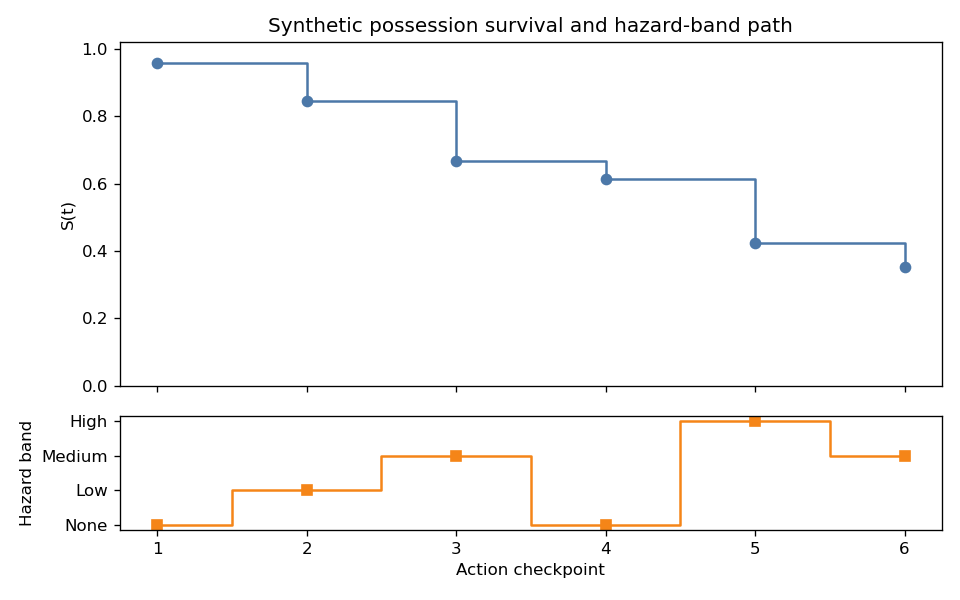

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.utils.possession import possession_survival

h=np.array([.04,.12,.21,.08,.31,.17])
summary=possession_survival(h)
S=summary["survival"]
bands=summary["bands"]
rank={"None":0,"Low":1,"Medium":2,"High":3}
fig,(ax,bx)=plt.subplots(2,1,figsize=(8,5),sharex=True,gridspec_kw={"height_ratios":[3,1]})
ax.step(np.arange(1,len(S)+1),S,where="post",marker="o",color="#4c78a8"); ax.set(ylabel="S(t)",ylim=(0,1.02),title="Synthetic possession survival and hazard-band path")
bx.step(np.arange(1,len(h)+1),[rank[b] for b in bands],where="mid",marker="s",color="#f58518"); bx.set(yticks=[0,1,2,3],yticklabels=["None","Low","Medium","High"],xlabel="Action checkpoint",ylabel="Hazard band")
fig.tight_layout()
out=Path("figures/vignette_07_survival.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out,dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Computed difficulty increments:", summary["difficulty_increment"])
print("Computed cumulative difficulty:", summary["cumulative_difficulty"])

## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.


In [5]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_checkpoints(possession_id).frame_id.iloc[0])
checkpoints = model.compute_possession(possession_id, xT_grid,
    ppcf_kwargs={"r_max": 12, "step": 6}, bcos_kwargs={"r_max": 8, "step": 4})
canonical = checkpoints.loc[checkpoints.is_canonical]
summary = possession_survival(canonical["Hazard"].to_numpy())
print(checkpoints.to_string(index=False))
print("computed survival:", summary["survival"])

alternative = model.compute_possession(possession_id, xT_grid, frame_ids=[5, 15, 25],
    ppcf_kwargs={"r_max": 12, "step": 6}, bcos_kwargs={"r_max": 8, "step": 4})
print("alternative frame selection:\n", alternative.to_string(index=False))
print("Alternative frames are evaluations; they are not added as consecutive survival steps.")


 possession_id  frame_id checkpoint_kind  is_canonical   p_pass   Hazard  Drive risk  Pass failure expected    rppcf
             1         0       canonical          True 0.327787 0.006091    0.001633               0.015234 0.984766
             1        10       canonical          True 0.256133 0.002522    0.000108               0.009531 0.990469
             1        20       canonical          True 0.397759 0.001862    0.000075               0.004569 0.995431
computed survival: [0.99390917 0.99140259 0.98955632]
alternative frame selection:
  possession_id  frame_id checkpoint_kind  is_canonical   p_pass   Hazard  Drive risk  Pass failure expected    rppcf
             1         5          custom         False 0.310703 0.004926    0.001292               0.012986 0.987014
             1        15          custom         False 0.244691 0.002082    0.000089               0.008233 0.991767
             1        25          custom         False 0.455288 0.001515    0.000064             

## Observation frames and canonical steps

The extended Fernandez framework defines the drive action over one second [@fernandez2021]. Frame-level inference can be performed anywhere; a retrospective survival interpretation additionally requires successive canonical risk steps. The source pipeline's shared boundaries and final partial intervals are project conventions to audit. The local estimate remains forward-looking even when evaluated on a replay. See [interpretation](../../interpretation.qmd). **model scope**